# EDA: Telco Customer Churn

## Введение

**Цель** — оценить качество и структуру данных датасета [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (Kaggle, BlastChar): типы, полноту, целостность, выбросы и аномалии, а также базовые метрики и связи между признаками.

**Что внутри:** 7 043 клиента телеком-оператора, 21 колонка: демография, подключённые услуги, тип контракта, платежи и целевой признак `Churn` (ушёл ли клиент).

**План**
1. Загрузка и структура данных
2. Полнота и целостность
3. Выбросы и аномалии
4. Метрики и распределения
5. Корреляции
6. Семантический анализ
7. Выводы

## 1. Загрузка и структура данных

In [23]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from data_loader import cast_types  # noqa: E402

RAW_PATH = ROOT / "data" / "raw" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(-1)

raw = pl.read_csv(RAW_PATH)  # raw data, types as inferred by Polars
raw.shape

(7043, 21)

**Сырые данные**, как их прочитал Polars

In [24]:
raw.head(10)

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
str,str,i64,str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str
"""7590-VHVEG""","""Female""",0,"""Yes""","""No""",1,"""No""","""No phone service""","""DSL""","""No""","""Yes""","""No""","""No""","""No""","""No""","""Month-to-month""","""Yes""","""Electronic check""",29.85,29.85,"""No"""
"""5575-GNVDE""","""Male""",0,"""No""","""No""",34,"""Yes""","""No""","""DSL""","""Yes""","""No""","""Yes""","""No""","""No""","""No""","""One year""","""No""","""Mailed check""",56.95,1889.5,"""No"""
"""3668-QPYBK""","""Male""",0,"""No""","""No""",2,"""Yes""","""No""","""DSL""","""Yes""","""Yes""","""No""","""No""","""No""","""No""","""Month-to-month""","""Yes""","""Mailed check""",53.85,108.15,"""Yes"""
"""7795-CFOCW""","""Male""",0,"""No""","""No""",45,"""No""","""No phone service""","""DSL""","""Yes""","""No""","""Yes""","""Yes""","""No""","""No""","""One year""","""No""","""Bank transfer (automatic)""",42.3,1840.75,"""No"""
"""9237-HQITU""","""Female""",0,"""No""","""No""",2,"""Yes""","""No""","""Fiber optic""","""No""","""No""","""No""","""No""","""No""","""No""","""Month-to-month""","""Yes""","""Electronic check""",70.7,151.65,"""Yes"""
"""9305-CDSKC""","""Female""",0,"""No""","""No""",8,"""Yes""","""Yes""","""Fiber optic""","""No""","""No""","""Yes""","""No""","""Yes""","""Yes""","""Month-to-month""","""Yes""","""Electronic check""",99.65,820.5,"""Yes"""
"""1452-KIOVK""","""Male""",0,"""No""","""Yes""",22,"""Yes""","""Yes""","""Fiber optic""","""No""","""Yes""","""No""","""No""","""Yes""","""No""","""Month-to-month""","""Yes""","""Credit card (automatic)""",89.1,1949.4,"""No"""
"""6713-OKOMC""","""Female""",0,"""No""","""No""",10,"""No""","""No phone service""","""DSL""","""Yes""","""No""","""No""","""No""","""No""","""No""","""Month-to-month""","""No""","""Mailed check""",29.75,301.9,"""No"""
"""7892-POOKP""","""Female""",0,"""Yes""","""No""",28,"""Yes""","""Yes""","""Fiber optic""","""No""","""No""","""Yes""","""Yes""","""Yes""","""Yes""","""Month-to-month""","""Yes""","""Electronic check""",104.8,3046.05,"""Yes"""


In [25]:
pl.DataFrame({
    "column": raw.columns,
    "raw_dtype": [str(t) for t in raw.dtypes],
    "n_unique": raw.select(pl.all().n_unique()).row(0),
})

column,raw_dtype,n_unique
str,str,i64
"""customerID""","""String""",7043
"""gender""","""String""",2
"""SeniorCitizen""","""Int64""",2
"""Partner""","""String""",2
"""Dependents""","""String""",2
"""tenure""","""Int64""",73
"""PhoneService""","""String""",2
"""MultipleLines""","""String""",3
"""InternetService""","""String""",3


In [26]:
typed = cast_types(raw)
print(f"Size in memory: raw={raw.estimated_size('kb'):.0f} KB, typed={typed.estimated_size('kb'):.0f} KB")
print("TotalCharges nulls after cast (expected 0):", typed["TotalCharges"].null_count())
pl.DataFrame({"column": typed.columns, "dtype": [str(t) for t in typed.dtypes]})

Size in memory: raw=933 KB, typed=514 KB
TotalCharges nulls after cast (expected 0): 0


column,dtype
str,str
"""customerID""","""String"""
"""gender""","""Categorical"""
"""SeniorCitizen""","""Boolean"""
"""Partner""","""Boolean"""
"""Dependents""","""Boolean"""
"""tenure""","""Int32"""
"""PhoneService""","""Boolean"""
"""MultipleLines""","""Categorical"""
"""InternetService""","""Categorical"""


## 2. Полнота и целостность

### 2.1 Пропуски и пустые строки

In [27]:
str_cols = [c for c, t in raw.schema.items() if t == pl.String]
nulls = raw.null_count().transpose(include_header=True, column_names=["nulls"])
blanks = pl.DataFrame({
    "column": str_cols,
    "blank_strings": [
        raw.select((pl.col(c).str.strip_chars() == "").sum()).item() for c in str_cols
    ],
})
nulls.join(blanks, on="column", how="left").filter(
    (pl.col("nulls") > 0) | (pl.col("blank_strings") > 0)
)

column,nulls,blank_strings
str,u32,i64
"""TotalCharges""",11,null


In [28]:
raw.filter(
    pl.col("TotalCharges").cast(pl.String).str.strip_chars().fill_null("") == ""
).select("customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn")

customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
str,i64,f64,f64,str,str
"""4472-LVYGI""",0,52.55,null,"""Two year""","""No"""
"""3115-CZMZD""",0,20.25,null,"""Two year""","""No"""
"""5709-LVOEQ""",0,80.85,null,"""Two year""","""No"""
"""4367-NUYAO""",0,25.75,null,"""Two year""","""No"""
"""1371-DWPAZ""",0,56.05,null,"""Two year""","""No"""
"""7644-OMVMY""",0,19.85,null,"""Two year""","""No"""
"""3213-VVOLG""",0,25.35,null,"""Two year""","""No"""
"""2520-SGTTA""",0,20.0,null,"""Two year""","""No"""
"""2923-ARZLG""",0,19.7,null,"""One year""","""No"""


### 2.2 Дубликаты

In [29]:
print("Duplicated customerID:", raw["customerID"].is_duplicated().sum())
print("Fully duplicated rows:  ", raw.is_duplicated().sum())
print("Duplicates ignoring customerID:", raw.drop("customerID").is_duplicated().sum())

Duplicated customerID: 0
Fully duplicated rows:   0
Duplicates ignoring customerID: 42


### 2.3 Согласованность значений категорий

In [30]:
cat_cols = [c for c in typed.columns if typed.schema[c] == pl.Categorical]
for c in cat_cols:
    print(f"{c}: {typed[c].cast(pl.String).unique().sort().to_list()}")

gender: ['Female', 'Male']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


In [31]:
padded = {
    c: raw.select((pl.col(c) != pl.col(c).str.strip_chars()).sum()).item()
    for c in str_cols
}
{c: n for c, n in padded.items() if n > 0} or "No leading/trailing whitespace found"

'No leading/trailing whitespace found'

### 2.4 Логические проверки между колонками

In [32]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]

bad_phone = typed.filter(
    ~pl.col("PhoneService") & (pl.col("MultipleLines") != "No phone service")
).height
bad_internet = typed.filter(
    (pl.col("InternetService") == "No")
    & pl.any_horizontal([pl.col(c) != "No internet service" for c in addons])
).height
bad_senior = raw.filter(~pl.col("SeniorCitizen").is_in([0, 1])).height
bad_tenure = typed.filter(
    (pl.col("tenure") == 0) != (pl.col("TotalCharges") == 0)
).height

pl.DataFrame({
    "check": [
        "No phone service -> MultipleLines = 'No phone service'",
        "No internet -> all add-ons = 'No internet service'",
        "SeniorCitizen is 0/1",
        "tenure = 0 <=> TotalCharges = 0",
    ],
    "violations": [bad_phone, bad_internet, bad_senior, bad_tenure],
})

check,violations
str,i64
"""No phone service -> MultipleLi…",0
"""No internet -> all add-ons = '…",0
"""SeniorCitizen is 0/1""",0
"""tenure = 0 <=> TotalCharges = …",0


In [33]:
ratio = typed.filter(pl.col("tenure") > 0).select(
    (pl.col("TotalCharges") / (pl.col("tenure") * pl.col("MonthlyCharges"))).alias("ratio")
)
print(ratio["ratio"].describe())
print("Rows where ratio is outside [0.5, 1.5]:",
      ratio.filter((pl.col("ratio") < 0.5) | (pl.col("ratio") > 1.5)).height)

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 7032.0   │
│ null_count ┆ 0.0      │
│ mean       ┆ 1.000275 │
│ std        ┆ 0.051159 │
│ min        ┆ 0.689356 │
│ 25%        ┆ 0.979548 │
│ 50%        ┆ 1.0      │
│ 75%        ┆ 1.019556 │
│ max        ┆ 1.573454 │
└────────────┴──────────┘
Rows where ratio is outside [0.5, 1.5]: 2


`TotalCharges` в среднем совпадает с `tenure × MonthlyCharges` (отношение около 1,0), но у отдельных клиентов отклоняется — это ожидаемо при смене тарифов и скидках.

## 3. Выбросы и аномалии

In [34]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
typed.select(num_cols).describe()

statistic,tenure,MonthlyCharges,TotalCharges
str,f64,f64,f64
"""count""",7043.0,7043.0,7043.0
"""null_count""",0.0,0.0,0.0
"""mean""",32.371149,64.761692,2279.734304
"""std""",24.559481,30.090047,2266.79447
"""min""",0.0,18.25,0.0
"""25%""",9.0,35.5,398.55
"""50%""",29.0,70.35,1394.55
"""75%""",55.0,89.85,3789.2
"""max""",72.0,118.75,8684.8


In [35]:
def iqr_report(s: pl.Series) -> dict:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {
        "column": s.name, "q1": q1, "q3": q3, "lower": lo, "upper": hi,
        "n_outliers": int(((s < lo) | (s > hi)).sum()),
    }

pl.DataFrame([iqr_report(typed[c]) for c in num_cols])

column,q1,q3,lower,upper,n_outliers
str,f64,f64,f64,f64,i64
"""tenure""",9.0,55.0,-60.0,124.0,0
"""MonthlyCharges""",35.5,89.85,-46.025,171.375,0
"""TotalCharges""",398.55,3789.2,-4687.425,8875.175,0


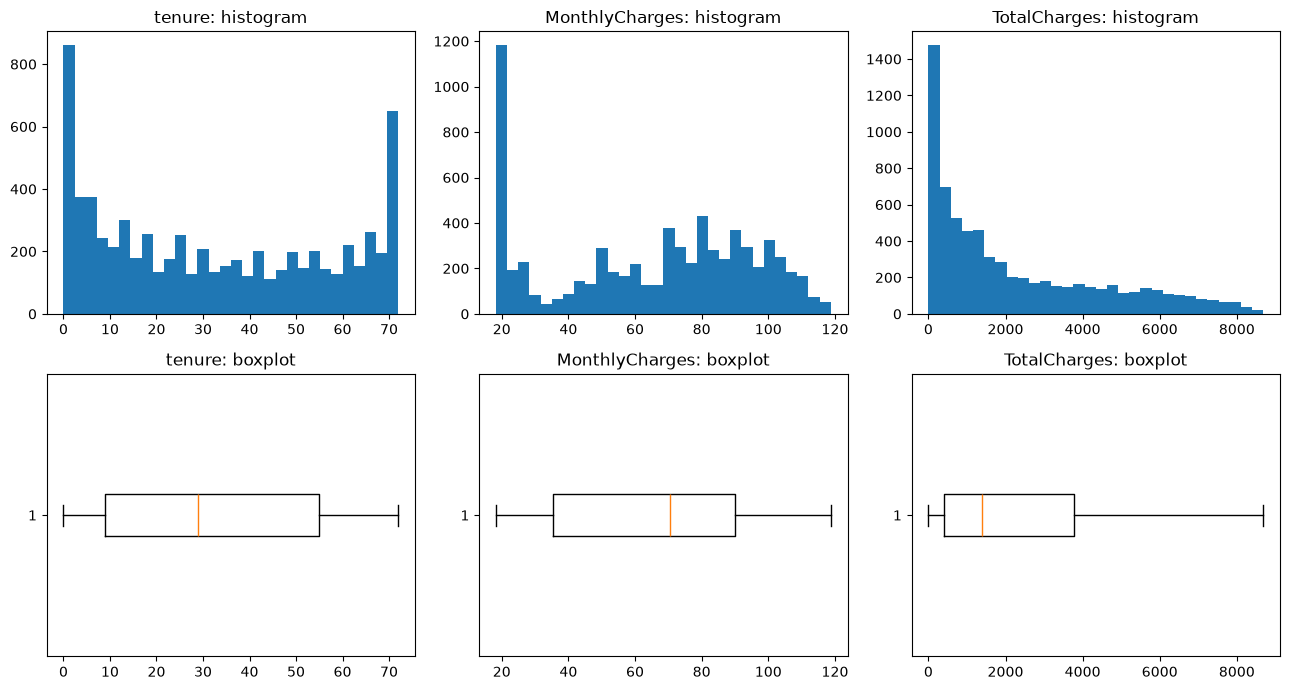

In [36]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for i, c in enumerate(num_cols):
    values = typed[c].drop_nulls().to_list()
    axes[0, i].hist(values, bins=30)
    axes[0, i].set_title(f"{c}: histogram")
    axes[1, i].boxplot(values, orientation="horizontal")
    axes[1, i].set_title(f"{c}: boxplot")
plt.tight_layout()
plt.show()

In [37]:
print("MonthlyCharges <= 0:", typed.filter(pl.col("MonthlyCharges") <= 0).height)
print("TotalCharges < 0:    ", typed.filter(pl.col("TotalCharges") < 0).height)
print("tenure out of [0, 72]:", typed.filter(~pl.col("tenure").is_between(0, 72)).height)
print("TotalCharges < MonthlyCharges (tenure > 0):",
      typed.filter((pl.col("tenure") > 0) & (pl.col("TotalCharges") < pl.col("MonthlyCharges"))).height)

MonthlyCharges <= 0: 0
TotalCharges < 0:     0
tenure out of [0, 72]: 0
TotalCharges < MonthlyCharges (tenure > 0): 0


## 4. Метрики и распределения

### 4.1 Целевая переменная

Churn rate: 26.5%  (churned=1869, total=7043)


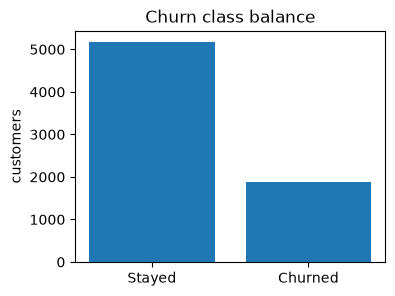

In [38]:
churn_rate = typed["Churn"].mean()
print(f"Churn rate: {churn_rate:.1%}  (churned={typed['Churn'].sum()}, total={typed.height})")

plt.figure(figsize=(4, 3))
plt.bar(["Stayed", "Churned"], [typed.height - typed["Churn"].sum(), typed["Churn"].sum()])
plt.title("Churn class balance")
plt.ylabel("customers")
plt.show()

### 4.2 Доля ушедших по группам

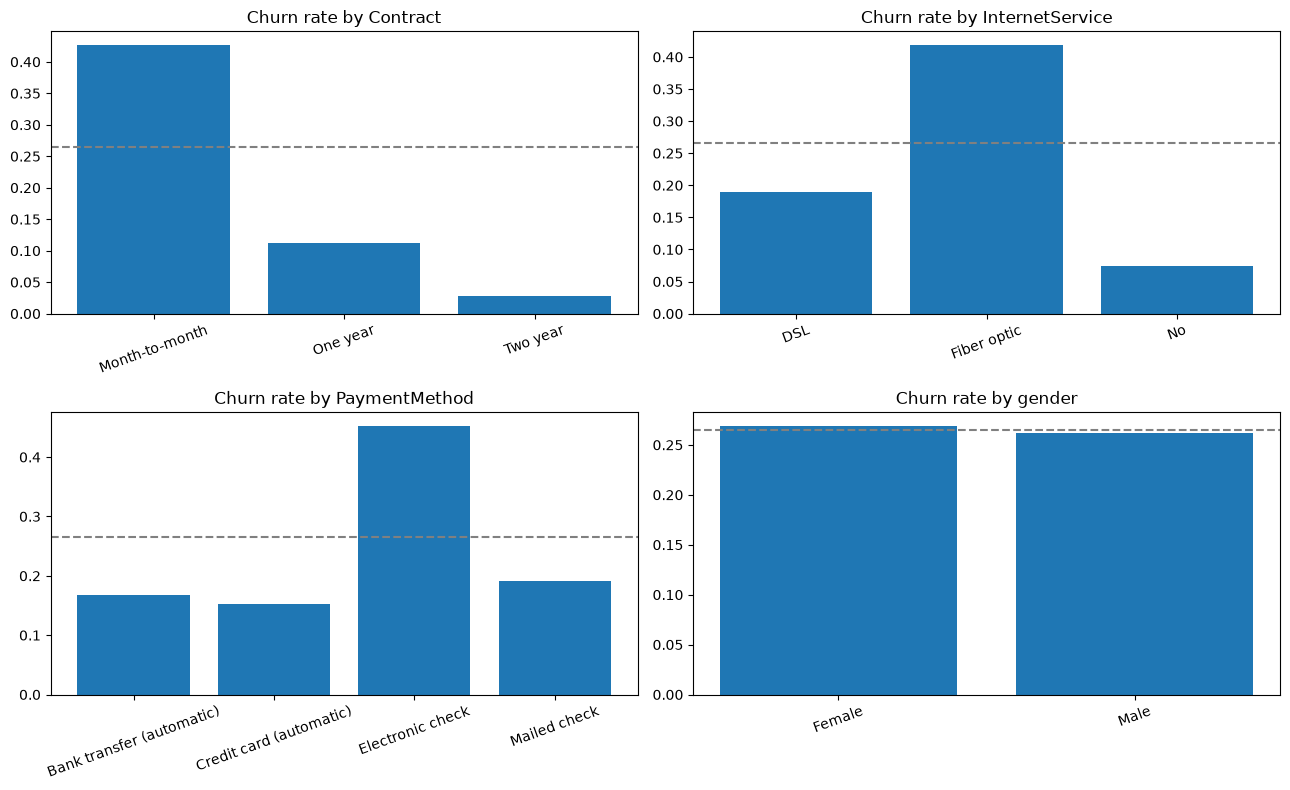

In [39]:
def churn_by(col: str) -> pl.DataFrame:
    return (
        typed.group_by(col)
        .agg(pl.len().alias("customers"), pl.col("Churn").mean().alias("churn_rate"))
        .with_columns(pl.col(col).cast(pl.String))
        .sort(col)
    )

group_cols = ["Contract", "InternetService", "PaymentMethod", "gender"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), group_cols):
    t = churn_by(c)
    ax.bar(t[c].to_list(), t["churn_rate"].to_list())
    ax.axhline(churn_rate, linestyle="--", color="gray")
    ax.set_title(f"Churn rate by {c}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

tenure_bin,customers,churn_rate
str,u32,f64
"""00-12""",2186,0.474382
"""13-24""",1024,0.287109
"""25-48""",1594,0.20389
"""49+""",2239,0.095132


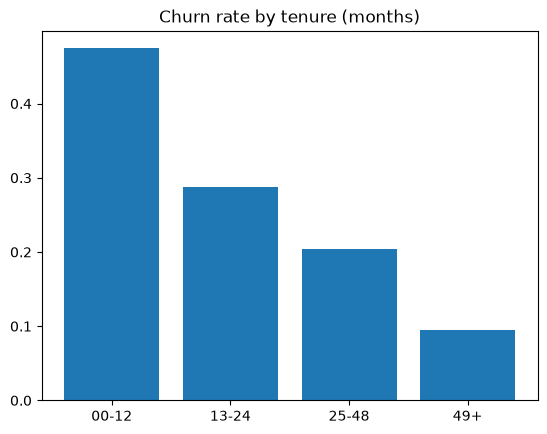

In [40]:
binned = typed.with_columns(
    pl.col("tenure")
    .cut([12, 24, 48], labels=["00-12", "13-24", "25-48", "49+"])
    .cast(pl.String)
    .alias("tenure_bin")
)
t = (
    binned.group_by("tenure_bin")
    .agg(pl.len().alias("customers"), pl.col("Churn").mean().alias("churn_rate"))
    .sort("tenure_bin")
)
display(t)
plt.bar(t["tenure_bin"].to_list(), t["churn_rate"].to_list())
plt.title("Churn rate by tenure (months)")
plt.show()

Доля ушедших выше при помесячном контракте, оптоволоконном интернете (Fiber optic) и оплате электронным чеком, сильно падает с ростом срока обслуживания; по полу различий почти нет.

### 4.3 Распределения остальных признаков

In [41]:
flag_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]
pl.DataFrame({"flag": flag_cols, "share_true": [typed[c].mean() for c in flag_cols]})

flag,share_true
str,f64
"""SeniorCitizen""",0.162147
"""Partner""",0.483033
"""Dependents""",0.299588
"""PhoneService""",0.903166
"""PaperlessBilling""",0.592219


In [42]:
for c in ["Contract", "InternetService", "PaymentMethod"]:
    display(typed[c].cast(pl.String).value_counts(sort=True))

Contract,count
str,u32
"""Month-to-month""",3875
"""Two year""",1695
"""One year""",1473


InternetService,count
str,u32
"""Fiber optic""",3096
"""DSL""",2421
"""No""",1526


PaymentMethod,count
str,u32
"""Electronic check""",2365
"""Mailed check""",1612
"""Bank transfer (automatic)""",1544
"""Credit card (automatic)""",1522


## 5. Корреляции

Для числовых и булевых признаков считаем корреляцию Пирсона (булевы приводятся к 0/1). Для бинарных признаков это фактически коэффициент phi.

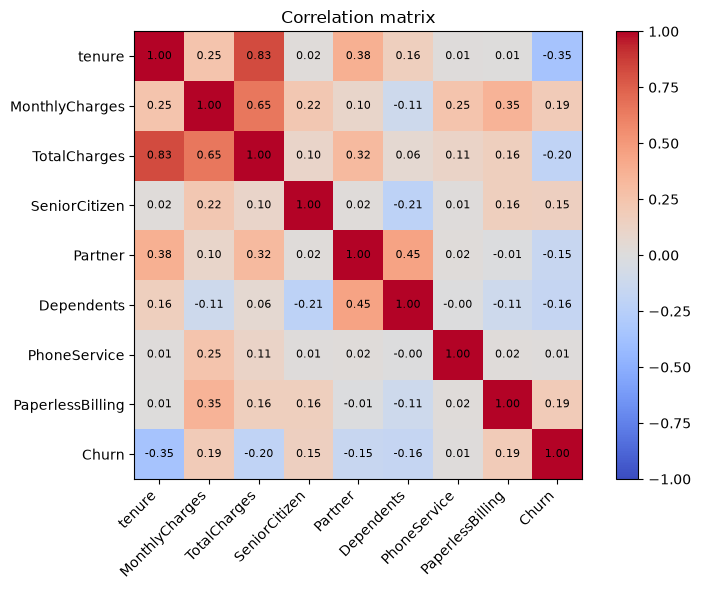

In [43]:
assert typed["TotalCharges"].null_count() == 0, "TotalCharges still has nulls"

bool_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
corr_df = typed.select(pl.col(num_cols), pl.col(bool_cols).cast(pl.Int8))
corr = corr_df.corr()
names = corr_df.columns
matrix = corr.to_numpy()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

In [44]:
churn_corr = {c: corr_df.select(pl.corr(c, "Churn")).item() for c in names if c != "Churn"}
pl.DataFrame({"feature": list(churn_corr), "corr_with_churn": list(churn_corr.values())}).sort(
    pl.col("corr_with_churn").abs(), descending=True
)

feature,corr_with_churn
str,f64
"""tenure""",-0.352229
"""TotalCharges""",-0.198324
"""MonthlyCharges""",0.193356
"""PaperlessBilling""",0.191825
"""Dependents""",-0.164221
"""SeniorCitizen""",0.150889
"""Partner""",-0.150448
"""PhoneService""",0.011942


## 6. Семантический анализ

- **Идентификатор:** `customerID` уникален и не несёт признаковой информации; в моделях его нужно исключать.
- **Бинарные признаки** (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`) хранились как `Yes/No`, `SeniorCitizen` — как 0/1; приведены к единому типу `Boolean`.
- **Трёхзначные признаки услуг** (`MultipleLines`, `OnlineSecurity` и др.) содержат значения `Yes`, `No` и `No phone service` / `No internet service`. Последнее значение **полностью определяется** `PhoneService` / `InternetService` — это структурная зависимость, а не отдельная категория. Поэтому колонки оставлены как `Categorical`, а не `Boolean`.
- **Производный признак:** `TotalCharges` ≈ `tenure × MonthlyCharges` — избыточность, при моделировании возможна мультиколлинеарность.
- **Чувствительные атрибуты:** `gender`, `SeniorCitizen` — при использовании в моделях нужно учитывать риск дискриминации.

## 7. Выводы

**Структура.** 7 043 строки × 21 колонка, один клиент на строку (`customerID` уникален). Исходные типы неудобны: флаги хранятся как `Yes/No` и 0/1, `TotalCharges` содержит пропуски. После приведения типов размер в памяти уменьшился с 933 KB до 514 KB.

**Полнота.** Единственная колонка с пропусками — `TotalCharges` (11 значений). Все они у клиентов с `tenure = 0`, то есть ещё не получавших счетов; значения заполнены нулём, после приведения `null` не осталось.

**Целостность.** Дубликатов `customerID` нет. Логические связи между `PhoneService` / `InternetService` и зависимыми услугами соблюдаются. 42 строки совпадают по всем колонкам, кроме идентификатора, — это разные клиенты с одинаковым профилем. `TotalCharges` в среднем равен `tenure × MonthlyCharges` (отношение около 1,0, диапазон примерно 0,69–1,57), отклонения объяснимы сменой тарифов.

**Выбросы.** По IQR выбросов нет ни в `tenure`, ни в `MonthlyCharges`, ни в `TotalCharges`; нулевых и отрицательных платежей нет, `tenure` лежит в диапазоне 0–72. Формы распределений объясняются природой признаков.

**Метрики.** Ушло 26,5 % клиентов (1 869 из 7 043), классы несбалансированы. Доля ушедших выше при помесячном контракте, оптоволоконном интернете и оплате электронным чеком; по сроку обслуживания она падает с 47 % (до 12 месяцев) до 9,5 % (свыше 48). Корреляция `tenure` с `Churn` — около −0,35.